In [2]:
import os

print("Files currently in Colab:")
for file in os.listdir("/content"):
    print(file)

Files currently in Colab:
.config
archive (16).zip
sample_data


In [3]:
import os

file_path = "/content/archive (16).zip"

print("File size:", os.path.getsize(file_path), "bytes")

with open(file_path, "rb") as f:
    print("File signature:", f.read(20))

File size: 5409593 bytes
File signature: b'PK\x03\x04-\x00\x00\x08\x08\x00\xc2\xac!Y\xe9\x91\xde\x8b\xff\xff'


In [4]:
import zipfile

file_path = "/content/archive (16).zip"

try:
    with zipfile.ZipFile(file_path, "r") as z:
        print("ZIP opened successfully!")
        print("Checking file integrity...")
        result = z.testzip()

        if result is None:
            print("ZIP integrity check passed!")
            print("\nFiles inside the ZIP:")
            for name in z.namelist():
                print(name)
        else:
            print("Corrupted file found:", result)

except zipfile.BadZipFile:
    print("The ZIP archive is invalid or incomplete.")

ZIP opened successfully!
Checking file integrity...
ZIP integrity check passed!

Files inside the ZIP:
traffic.csv


In [5]:

import zipfile
import os
import pandas as pd

zip_path = "/content/archive (16).zip"
extract_path = "/content/website_traffic"

# Extract the original dataset
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

# Load the CSV
csv_path = os.path.join(extract_path, "traffic.csv")
df = pd.read_csv(csv_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())


Dataset loaded successfully!
Dataset shape: (226278, 9)

Column names:
['event', 'date', 'country', 'city', 'artist', 'album', 'track', 'isrc', 'linkid']

First 5 rows:


,event,date,country,city,artist,album,track,isrc,linkid
0,click,2021-08-21,Saudi Arabia,Jeddah,Tesher,Jalebi Baby,Jalebi Baby,QZNWQ2070741,2d896d31-97b6-4869-967b-1c5fb9cd4bb8
1,click,2021-08-21,Saudi Arabia,Jeddah,Tesher,Jalebi Baby,Jalebi Baby,QZNWQ2070741,2d896d31-97b6-4869-967b-1c5fb9cd4bb8
2,click,2021-08-21,India,Ludhiana,Reyanna Maria,So Pretty,So Pretty,USUM72100871,23199824-9cf5-4b98-942a-34965c3b0cc2
3,click,2021-08-21,France,Unknown,"Simone & Simaria, Sebastian Yatra",No Llores Más,No Llores Más,BRUM72003904,35573248-4e49-47c7-af80-08a960fa74cd
4,click,2021-08-21,Maldives,Malé,Tesher,Jalebi Baby,Jalebi Baby,QZNWQ2070741,2d896d31-97b6-4869-967b-1c5fb9cd4bb8



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 226278 entries, 0 to 226277
Data columns (total 9 columns):
 #   Column   Non-Null Count   Dtype 
---  ------   --------------   ----- 
 0   event    226278 non-null  object
 1   date     226278 non-null  object
 2   country  226267 non-null  object
 3   city     226267 non-null  object
 4   artist   226241 non-null  object
 5   album    226273 non-null  object
 6   track    226273 non-null  object
 7   isrc     219157 non-null  object
 8   linkid   226278 non-null  object
dtypes: object(9)
memory usage: 15.5+ MB

Missing values:


,0
event,0
date,0
country,11
city,11
artist,37
album,5
track,5
isrc,7121
linkid,0



Duplicate rows: 103711


In [6]:

# Step 3: Data Cleaning and Validation

# Preserve the original dataset
df_raw = df.copy()

# Create a working copy
df_clean = df.copy()

# 1. Convert date column to datetime
df_clean["date"] = pd.to_datetime(
    df_clean["date"], errors="coerce"
)

# 2. Remove exact duplicate rows
rows_before = len(df_clean)
df_clean = df_clean.drop_duplicates().copy()
duplicates_removed = rows_before - len(df_clean)

# 3. Standardize text columns
text_columns = [
    "event", "country", "city",
    "artist", "album", "track", "isrc"
]

for col in text_columns:
    df_clean[col] = df_clean[col].astype("string").str.strip()
    df_clean[col] = df_clean[col].replace("", pd.NA)

# 4. Standardize event names
df_clean["event"] = df_clean["event"].str.lower()

# 5. Handle missing values in descriptive columns
# Keep missing values as "Unknown" so records aren't unnecessarily lost
fill_columns = [
    "country", "city", "artist",
    "album", "track", "isrc"
]

for col in fill_columns:
    df_clean[col] = df_clean[col].fillna("Unknown")

# 6. Check results
print("CLEANING SUMMARY")
print("-" * 40)
print("Original rows:", len(df_raw))
print("Exact duplicate rows removed:", duplicates_removed)
print("Rows after cleaning:", len(df_clean))
print("Columns:", df_clean.shape[1])
print("Missing values after cleaning:", df_clean.isnull().sum().sum())

print("\nEvent counts after cleaning:")
display(df_clean["event"].value_counts().to_frame("Event Count"))

print("\nDate range:")
print("Start:", df_clean["date"].min())
print("End:", df_clean["date"].max())

print("\nUnique link IDs:", df_clean["linkid"].nunique())

print("\nRemaining duplicate rows:", df_clean.duplicated().sum())


CLEANING SUMMARY
----------------------------------------
Original rows: 226278
Exact duplicate rows removed: 103711
Rows after cleaning: 122567
Columns: 9
Missing values after cleaning: 0

Event counts after cleaning:


,Event Count
event,
pageview,73360
click,32499
preview,16708



Date range:
Start: 2021-08-19 00:00:00
End: 2021-08-25 00:00:00

Unique link IDs: 3839

Remaining duplicate rows: 0


In [7]:

# Step 4: Website Traffic KPIs

# 1. Overall event metrics
total_events = len(df_clean)
unique_links = df_clean["linkid"].nunique()
unique_artists = df_clean["artist"].nunique()
unique_tracks = df_clean["track"].nunique()
active_days = df_clean["date"].nunique()

print("WEBSITE TRAFFIC KPI SUMMARY")
print("=" * 45)
print(f"Total events after deduplication: {total_events:,}")
print(f"Unique link IDs: {unique_links:,}")
print(f"Unique artists (including Unknown): {unique_artists:,}")
print(f"Unique tracks (including Unknown): {unique_tracks:,}")
print(f"Days covered: {active_days}")
print(f"Average recorded events per day: {total_events / active_days:,.2f}")

# 2. Event counts and proportions
event_summary = (
    df_clean["event"]
    .value_counts()
    .rename_axis("Event")
    .reset_index(name="Event Count")
)

event_summary["Percentage"] = (
    event_summary["Event Count"] / total_events * 100
).round(2)

print("\nEVENT BREAKDOWN")
display(event_summary)

# 3. Daily event activity
daily_traffic = (
    df_clean.groupby(["date", "event"])
    .size()
    .unstack(fill_value=0)
    .sort_index()
)

daily_traffic["Total Events"] = daily_traffic.sum(axis=1)

print("\nDAILY TRAFFIC")
display(daily_traffic)

# 4. Link performance by event type
link_performance = (
    df_clean.pivot_table(
        index="linkid",
        columns="event",
        values="date",
        aggfunc="size",
        fill_value=0
    )
)

for event_name in ["pageview", "click", "preview"]:
    if event_name not in link_performance.columns:
        link_performance[event_name] = 0

link_performance["Total Events"] = link_performance[
    ["pageview", "click", "preview"]
].sum(axis=1)

link_performance = link_performance.sort_values(
    "Total Events", ascending=False
)

print("\nTOP 10 LINKS BY RECORDED EVENTS")
display(link_performance.head(10))

# 5. Content performance
content_performance = (
    df_clean.groupby(["artist", "track"])
    .agg(
        Total_Events=("event", "size"),
        Unique_Links=("linkid", "nunique")
    )
    .sort_values("Total_Events", ascending=False)
)

print("\nTOP 10 ARTIST-TRACK COMBINATIONS")
display(content_performance.head(10))


WEBSITE TRAFFIC KPI SUMMARY
Total events after deduplication: 122,567
Unique link IDs: 3,839
Unique artists (including Unknown): 2,420
Unique tracks (including Unknown): 3,563
Days covered: 7
Average recorded events per day: 17,509.57

EVENT BREAKDOWN


,Event,Event Count,Percentage
0,pageview,73360,59.85
1,click,32499,26.52
2,preview,16708,13.63



DAILY TRAFFIC


event,click,pageview,preview,Total Events
date,,,,
2021-08-19,5860,13006,2290,21156
2021-08-20,4999,11088,2449,18536
2021-08-21,4279,9939,2483,16701
2021-08-22,4421,9982,2524,16927
2021-08-23,4314,9722,2379,16415
2021-08-24,4231,9705,2355,16291
2021-08-25,4395,9918,2228,16541



TOP 10 LINKS BY RECORDED EVENTS


event,click,pageview,preview,Total Events
linkid,,,,
2d896d31-97b6-4869-967b-1c5fb9cd4bb8,2266,4576,1446,8288
e849515b-929d-44c8-a505-e7622f1827e9,1062,2137,751,3950
522da5cc-8177-4140-97a7-a84fdb4caf1c,891,2142,753,3786
a82e72d8-523f-43ab-9fd0-992605d54b4e,908,1736,415,3059
681d888a-59ce-4acb-b7c5-95dab0c063d9,873,1637,355,2865
23199824-9cf5-4b98-942a-34965c3b0cc2,684,1559,432,2675
c2c876ab-b093-4750-9449-6b4913da6af3,579,1391,472,2442
97105aff-3e40-4c2e-bfeb-563b55e8f5dd,549,1428,413,2390
d5317591-872a-487d-87cb-10a516643d5f,566,1155,353,2074



TOP 10 ARTIST-TRACK COMBINATIONS


,,Total_Events,Unique_Links
artist,track,,
Tesher,Jalebi Baby,8288,1
Anne-Marie,Beautiful,4028,2
Tundra Beats,Beautiful Day,3950,1
Roddy Ricch,Late At Night,3059,1
"Surf Mesa, Emilee",ily (i love you baby) (feat. Emilee),2956,3
"DMNDS, Strange Fruits Music, Fallen Roses, Lujavo, Nito-Onna",Calabria (feat. Lujavo & Nito-Onna),2865,1
Reyanna Maria,So Pretty,2675,1
"50 Cent, Olivia",Candy Shop,2390,1
"Shawn Mendes, Tainy",Summer of Love (Shawn Mendes & Tainy),2108,2


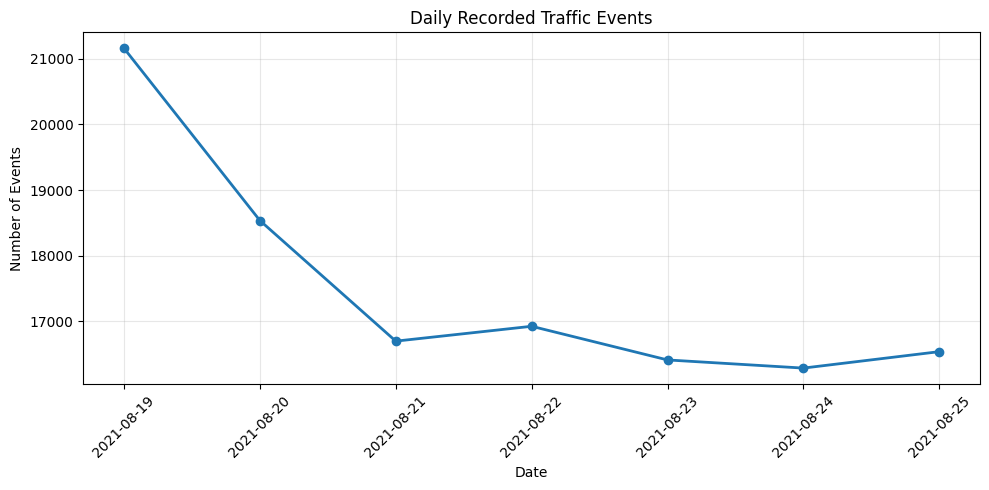

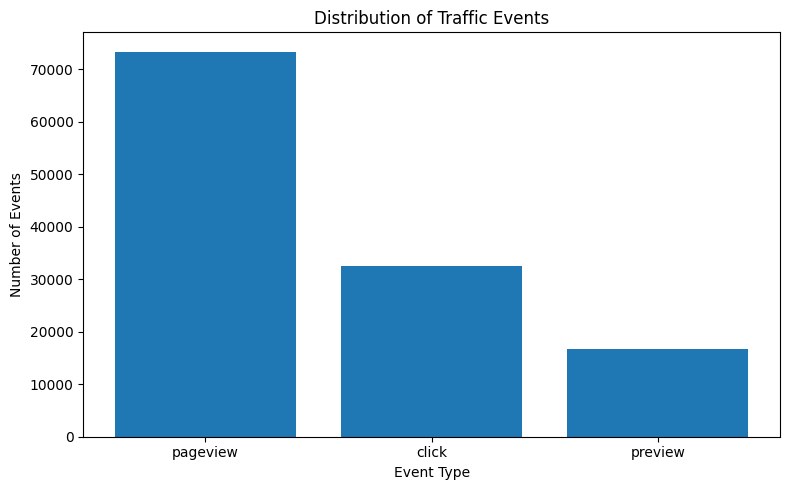

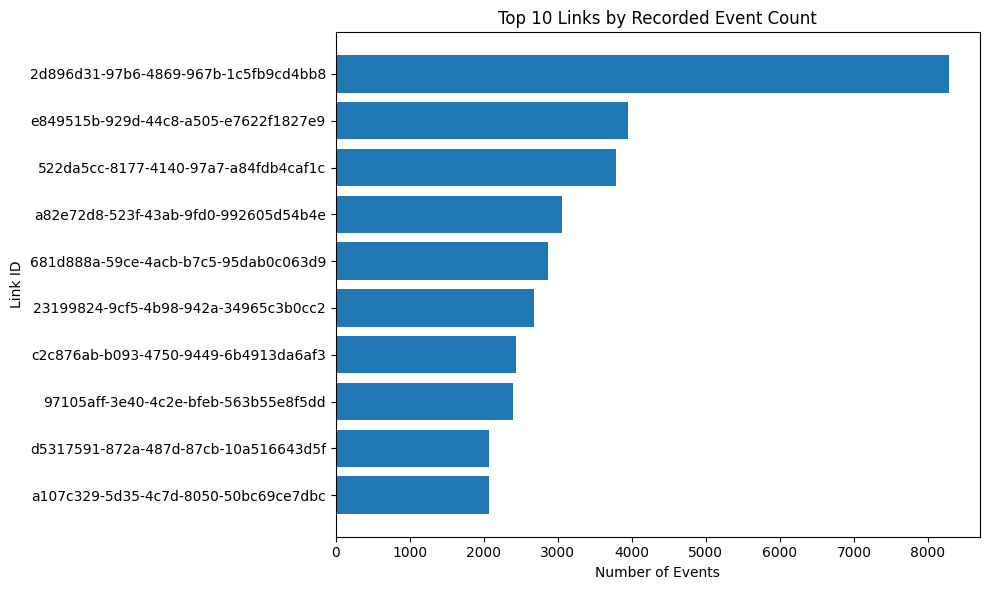

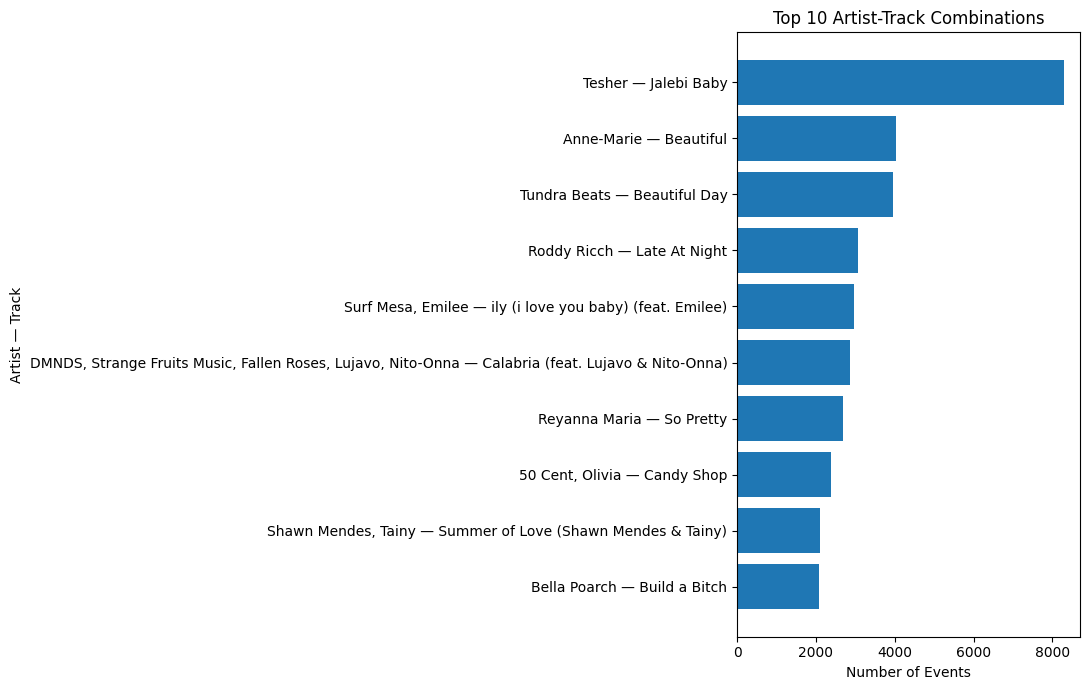

All 4 visualizations generated successfully!


In [8]:

# Step 5: Traffic Analysis Visualizations

import matplotlib.pyplot as plt
import pandas as pd

# Chart 1: Daily traffic trend
daily_totals = df_clean.groupby("date").size().sort_index()

plt.figure(figsize=(10, 5))
plt.plot(
    daily_totals.index,
    daily_totals.values,
    marker="o",
    linewidth=2
)
plt.title("Daily Recorded Traffic Events")
plt.xlabel("Date")
plt.ylabel("Number of Events")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Chart 2: Event distribution
event_counts = df_clean["event"].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(event_counts.index, event_counts.values)
plt.title("Distribution of Traffic Events")
plt.xlabel("Event Type")
plt.ylabel("Number of Events")
plt.tight_layout()
plt.show()


# Chart 3: Top 10 links by recorded events
top_links = (
    df_clean["linkid"]
    .value_counts()
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
plt.barh(top_links.index.astype(str), top_links.values)
plt.title("Top 10 Links by Recorded Event Count")
plt.xlabel("Number of Events")
plt.ylabel("Link ID")
plt.tight_layout()
plt.show()


# Chart 4: Top 10 artist-track combinations
top_content = (
    df_clean.groupby(["artist", "track"])
    .size()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

labels = [
    f"{artist} — {track}"
    for artist, track in top_content.index
]

plt.figure(figsize=(11, 7))
plt.barh(labels, top_content.values)
plt.title("Top 10 Artist-Track Combinations")
plt.xlabel("Number of Events")
plt.ylabel("Artist — Track")
plt.tight_layout()
plt.show()

print("All 4 visualizations generated successfully!")


TOP 10 COUNTRIES


,Total_Events,Unique_Links
country,,
United States,28664,2895
India,18689,408
France,10565,361
Saudi Arabia,7682,455
United Kingdom,5095,312
Germany,4017,283
Canada,2784,448
Pakistan,2633,237
Iraq,2444,230



TOP 10 CITIES


,country,city,Total_Events
7245,Saudi Arabia,Jeddah,2497
7257,Saudi Arabia,Riyadh,2232
4873,India,Hyderabad,1013
7243,Saudi Arabia,Dammam,1002
4797,India,Delhi,882
4885,India,Jaipur,849
4957,India,Lucknow,837
5552,Kuwait,Kuwait City,816
4667,India,Ahmedabad,808
5061,India,Pune,799



TOP 10 COUNTRIES: EVENT BREAKDOWN


event,click,pageview,preview,Total Events
country,,,,
United States,8446,18131,2087,28664
India,5360,10565,2764,18689
France,2792,6181,1592,10565
Saudi Arabia,1976,3712,1994,7682
United Kingdom,1307,3218,570,5095
Germany,1030,2585,402,4017
Canada,840,1702,242,2784
Pakistan,754,1382,497,2633
Iraq,567,1285,592,2444



DESCRIPTIVE ENGAGEMENT INDICATORS
----------------------------------------
Clicks per 100 recorded pageviews: 44.30
Previews per 100 recorded pageviews: 22.78

Important: These are event-count ratios, not user-level conversion rates.
The dataset has no user IDs, session IDs, or event timestamps.


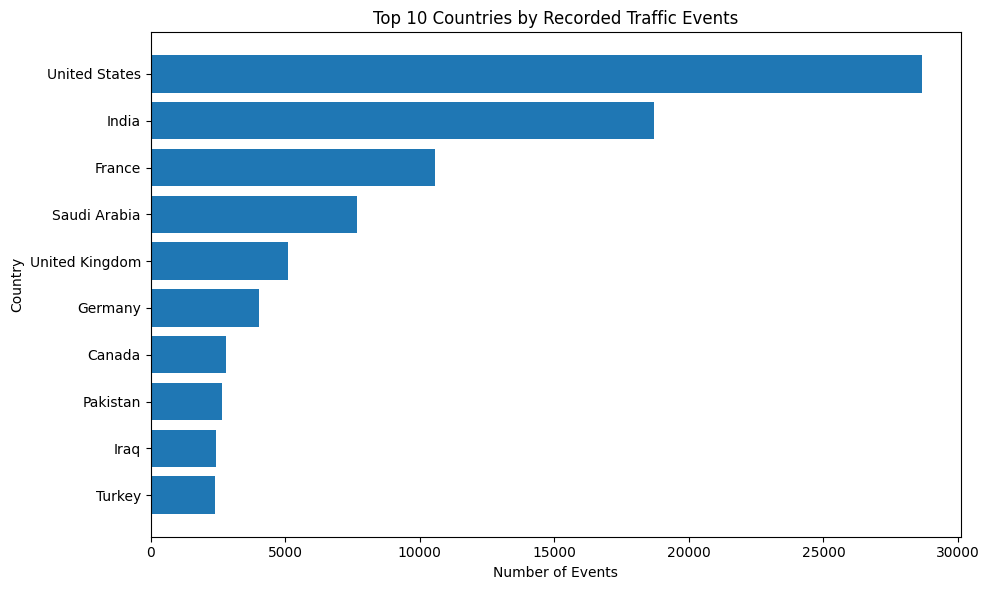


Geographic analysis completed!


In [9]:

# Step 6: Geographic Analysis and Engagement Indicators

# 1. Top 10 countries by recorded events
country_summary = (
    df_clean.groupby("country")
    .agg(
        Total_Events=("event", "size"),
        Unique_Links=("linkid", "nunique")
    )
    .sort_values("Total_Events", ascending=False)
)

print("TOP 10 COUNTRIES")
display(country_summary.head(10))

# 2. Top 10 cities by recorded events
city_summary = (
    df_clean[df_clean["city"] != "Unknown"]
    .groupby(["country", "city"])
    .size()
    .reset_index(name="Total_Events")
    .sort_values("Total_Events", ascending=False)
)

print("\nTOP 10 CITIES")
display(city_summary.head(10))

# 3. Event counts by country and event type
country_event_summary = pd.crosstab(
    df_clean["country"],
    df_clean["event"]
)

country_event_summary["Total Events"] = country_event_summary.sum(axis=1)

print("\nTOP 10 COUNTRIES: EVENT BREAKDOWN")
top_countries = country_event_summary.sort_values(
    "Total Events", ascending=False
).head(10)

display(top_countries)

# 4. Descriptive event ratios
event_counts = df_clean["event"].value_counts()

pageviews = int(event_counts.get("pageview", 0))
clicks = int(event_counts.get("click", 0))
previews = int(event_counts.get("preview", 0))

click_to_pageview_ratio = (
    clicks / pageviews * 100 if pageviews else 0
)

preview_to_pageview_ratio = (
    previews / pageviews * 100 if pageviews else 0
)

print("\nDESCRIPTIVE ENGAGEMENT INDICATORS")
print("-" * 40)
print(f"Clicks per 100 recorded pageviews: {click_to_pageview_ratio:.2f}")
print(f"Previews per 100 recorded pageviews: {preview_to_pageview_ratio:.2f}")
print("\nImportant: These are event-count ratios, not user-level conversion rates.")
print("The dataset has no user IDs, session IDs, or event timestamps.")

# 5. Visualize top countries
top_country_counts = (
    df_clean["country"]
    .value_counts()
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
plt.barh(top_country_counts.index, top_country_counts.values)
plt.title("Top 10 Countries by Recorded Traffic Events")
plt.xlabel("Number of Events")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

print("\nGeographic analysis completed!")


In [10]:

# Step 8: Final Validation and Export of Analysis Tables

import os

# Confirm the dataset used for analysis
print("FINAL DATA VALIDATION")
print("=" * 40)
print("Original records:", len(df_raw))
print("Cleaned records:", len(df_clean))
print("Exact duplicate rows removed:", len(df_raw) - len(df_clean))
print("Date range:", df_clean["date"].min().date(), "to",
      df_clean["date"].max().date())
print("Unique links:", df_clean["linkid"].nunique())
print("Missing values:", df_clean.isnull().sum().sum())
print("Remaining exact duplicates:", df_clean.duplicated().sum())

print("\nEvent counts:")
display(df_clean["event"].value_counts().to_frame("Count"))

# Save analysis tables for documentation
output_dir = "/content/website_traffic_outputs"
os.makedirs(output_dir, exist_ok=True)

daily_traffic.to_csv(
    os.path.join(output_dir, "daily_traffic.csv")
)

event_summary.to_csv(
    os.path.join(output_dir, "event_summary.csv"),
    index=False
)

country_summary.to_csv(
    os.path.join(output_dir, "country_summary.csv")
)

city_summary.to_csv(
    os.path.join(output_dir, "city_summary.csv"),
    index=False
)

link_performance.head(10).to_csv(
    os.path.join(output_dir, "top_10_links.csv")
)

content_performance.head(10).to_csv(
    os.path.join(output_dir, "top_artist_tracks.csv")
)

print("\nAnalysis tables saved to:", output_dir)
print("Validation completed!")


FINAL DATA VALIDATION
Original records: 226278
Cleaned records: 122567
Exact duplicate rows removed: 103711
Date range: 2021-08-19 to 2021-08-25
Unique links: 3839
Missing values: 0
Remaining exact duplicates: 0

Event counts:


,Count
event,
pageview,73360
click,32499
preview,16708



Analysis tables saved to: /content/website_traffic_outputs
Validation completed!


In [11]:

# Step 9: Save the cleaned dataset and visualization images

import os
import matplotlib.pyplot as plt
import zipfile

output_dir = "/content/website_traffic_outputs"
os.makedirs(output_dir, exist_ok=True)

# Save the cleaned dataset
df_clean.to_csv(
    os.path.join(output_dir, "cleaned_traffic.csv"),
    index=False
)

# Save all currently open Matplotlib figures
# (If figures were already closed, rerun the chart cell first.)
figures = plt.get_fignums()

for i, fig_num in enumerate(figures, start=1):
    fig = plt.figure(fig_num)
    fig.savefig(
        os.path.join(output_dir, f"traffic_chart_{i}.png"),
        dpi=200,
        bbox_inches="tight"
    )

print("Cleaned dataset saved.")
print("Open figures found:", len(figures))
print("\nFiles currently in output folder:")
for filename in sorted(os.listdir(output_dir)):
    print(filename)

# Create one ZIP containing the output files
zip_output = "/content/Website_Traffic_Analysis_Outputs.zip"

with zipfile.ZipFile(zip_output, "w", zipfile.ZIP_DEFLATED) as zipf:
    for filename in os.listdir(output_dir):
        file_path = os.path.join(output_dir, filename)
        if os.path.isfile(file_path):
            zipf.write(file_path, arcname=filename)

print("\nZIP created:", zip_output)


Cleaned dataset saved.
Open figures found: 0

Files currently in output folder:
city_summary.csv
cleaned_traffic.csv
country_summary.csv
daily_traffic.csv
event_summary.csv
top_10_links.csv
top_artist_tracks.csv

ZIP created: /content/Website_Traffic_Analysis_Outputs.zip
